In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
df=pd.read_csv("../DATA/sales.csv")
df.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [129]:
print(df.isna().sum())
print(df.shape)
df.info()
print(df.duplicated().sum())

Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64
(1000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   str    
 2   Sales_Rep             1000 non-null   str    
 3   Region                1000 non-null   str    
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   str    
 7   Unit_Cost             1000 non-null   float64
 8   Un

so the data is clean and has no duplicated , and its has 1000 rows and 14 culmns

In [130]:
print(df[df["Sales_Amount"]<0])
print(df[df["Quantity_Sold"]<0])
print(df[df["Unit_Cost"]<0])
print(df[df["Unit_Price"]<0])
print((~df["Discount"].between(0,1).sum()))
print(df["Product_ID"].nunique())

Empty DataFrame
Columns: [Product_ID, Sale_Date, Sales_Rep, Region, Sales_Amount, Quantity_Sold, Product_Category, Unit_Cost, Unit_Price, Customer_Type, Discount, Payment_Method, Sales_Channel, Region_and_Sales_Rep]
Index: []
Empty DataFrame
Columns: [Product_ID, Sale_Date, Sales_Rep, Region, Sales_Amount, Quantity_Sold, Product_Category, Unit_Cost, Unit_Price, Customer_Type, Discount, Payment_Method, Sales_Channel, Region_and_Sales_Rep]
Index: []
Empty DataFrame
Columns: [Product_ID, Sale_Date, Sales_Rep, Region, Sales_Amount, Quantity_Sold, Product_Category, Unit_Cost, Unit_Price, Customer_Type, Discount, Payment_Method, Sales_Channel, Region_and_Sales_Rep]
Index: []
Empty DataFrame
Columns: [Product_ID, Sale_Date, Sales_Rep, Region, Sales_Amount, Quantity_Sold, Product_Category, Unit_Cost, Unit_Price, Customer_Type, Discount, Payment_Method, Sales_Channel, Region_and_Sales_Rep]
Index: []
-1001
100


All the numbre are positive so the data is actualy right

In [131]:
totale_revenue=(df["Quantity_Sold"] * df["Unit_Price"]).sum()
totale_cost=(df["Quantity_Sold"]*df["Unit_Cost"]).sum()
x=totale_revenue-totale_cost
totale_profit=round(x,2)
print(f"{totale_revenue} is totale revenue")
print(f"{totale_cost} is totale cost")
print(f"{totale_profit} is totale profite")
margine=round((totale_profit/totale_revenue)*100,2)
print(f"{margine} %is the margine")



70329940.71 is totale revenue
63842093.64 is totale cost
6487847.07 is totale profite
9.22 %is the margine


In [132]:
print(round(df.describe(),2))

       Product_ID  Sales_Amount  Quantity_Sold  Unit_Cost  Unit_Price  \
count     1000.00       1000.00        1000.00    1000.00     1000.00   
mean      1050.13       5019.27          25.36    2475.30     2728.44   
std         29.57       2846.79          14.16    1417.87     1419.40   
min       1001.00        100.12           1.00      60.28      167.12   
25%       1024.00       2550.30          13.00    1238.38     1509.08   
50%       1051.00       5019.30          25.00    2467.23     2696.40   
75%       1075.00       7507.45          38.00    3702.86     3957.97   
max       1100.00       9989.04          49.00    4995.30     5442.15   

       Discount  
count   1000.00  
mean       0.15  
std        0.09  
min        0.00  
25%        0.08  
50%        0.15  
75%        0.23  
max        0.30  


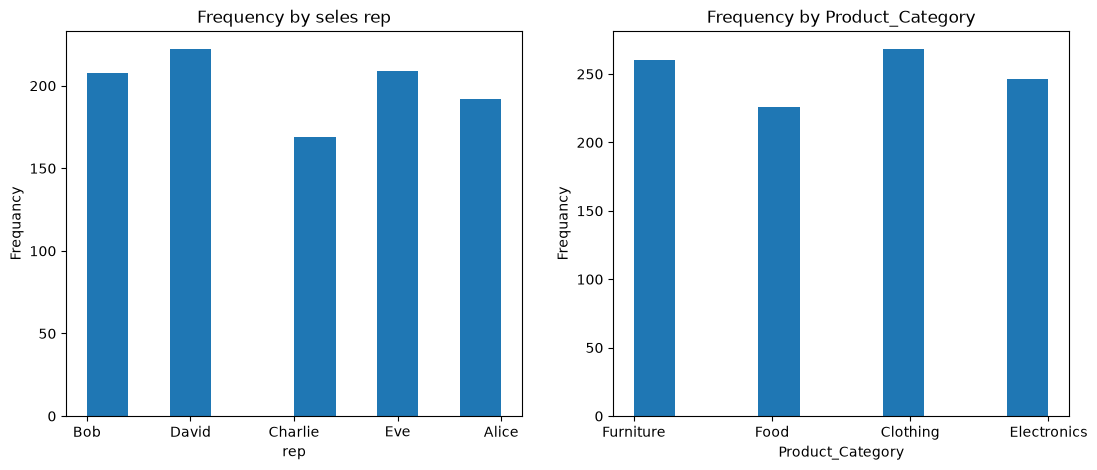

In [133]:
plt.figure(figsize=(20,5))
plt.subplot(1,3,1)
plt.hist(df["Sales_Rep"])
plt.title('Frequency by seles rep')
plt.xlabel("rep")
plt.ylabel("Frequancy")
plt.subplot(1,3,2)
plt.hist(df["Product_Category"])
plt.title('Frequency by Product_Category')
plt.xlabel("Product_Category")
plt.ylabel("Frequancy")
plt.savefig("../graphes/graphe1")
plt.show()

the david is the one who sell and bob after him by a litle difrence,and the cloting and the furniture is the most producte that bought it

In [134]:
df["Date"] = pd.to_datetime(df["Sale_Date"])
df["month"] = df["Date"].dt.month

monthly = df.groupby("month").agg(
    Sales_Amount_avg=("Sales_Amount", "mean"),
    Sales_Amount_total=("Sales_Amount", "sum"),
    Quantity_Sold_avg=("Quantity_Sold", "mean"),
    Quantity_Sold_total=("Quantity_Sold", "sum")
)

print(monthly.round(2))

       Sales_Amount_avg  Sales_Amount_total  Quantity_Sold_avg  \
month                                                            
1               4809.91           495420.37              24.75   
2               4918.92           368919.36              27.52   
3               5032.98           402638.77              25.86   
4               5419.66           438992.61              24.41   
5               5403.87           389078.76              27.33   
6               4548.46           418458.34              24.74   
7               5503.57           374242.88              23.57   
8               4765.28           443171.28              25.12   
9               5409.38           367837.60              26.69   
10              5231.58           460378.78              27.11   
11              4920.87           467482.90              22.41   
12              4619.34           392643.58              25.68   

       Quantity_Sold_total  
month                       
1                

The highst sales in the month is January by 495420.37 and the total of the quantity sold is also the higher by 2549  
also we can conclude that the if the Quantity_Sold_total is being higher doseant mean that the revenue will be higher
exempl month 4 1977 unit sold  and their revenue is  438992.61  compare it white monthe 3  2069 402638.77


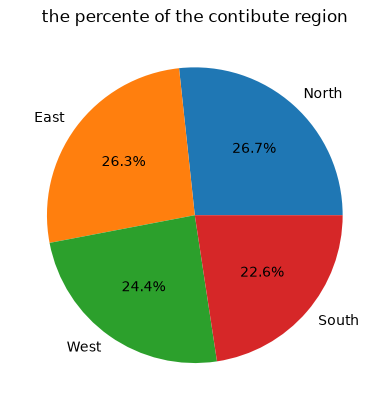

In [135]:

values=df["Region"].value_counts()
plt.pie(values,labels=values.index,autopct="%1.1f%%")
plt.title("the percente of the contibute region")
plt.savefig("../graphes/graphe2")
plt.show()

the north region has more pursches by 26.7% than the other regions and the last oneis the esat by the 22.6%

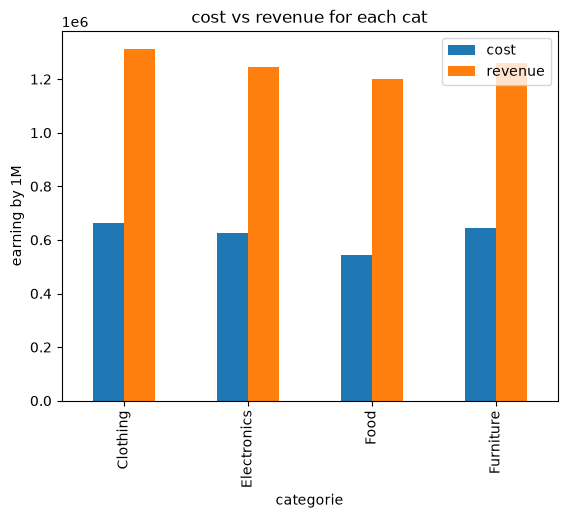

In [136]:
Product_category_performance=df.groupby("Product_Category").agg(
    cost=("Unit_Cost","sum"),
    revenue=("Sales_Amount","sum"),
).plot(kind="bar")
plt.title("cost vs revenue for each cat")
plt.ylabel("earning by 1M")
plt.xlabel("categorie")
plt.savefig("../graphes/graphe3")
plt.show()


the clothing is the most selling by 6922 unit and alsois number one in their revenue by 1313474
and we can to see the campony is profutable for each product


           totale_sales  avg_sales  quantity_sales  max_sales
Sales_Rep                                                    
David        1141737.36    5142.96            6042    9989.04
Bob          1080990.63    5197.07            4977    9956.75
Eve           970183.99    4642.03            5287    9933.22
Alice         965541.77    5028.86            4832    9972.66
Charlie       860811.48    5093.56            4217    9972.11


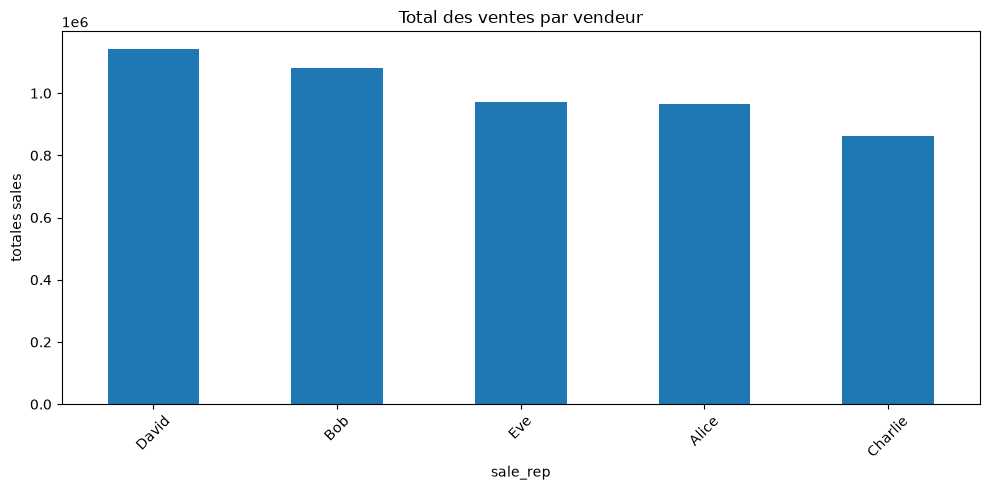

In [137]:
per_rep=df.groupby("Sales_Rep").agg(
    totale_sales=("Sales_Amount","sum"),
    avg_sales=("Sales_Amount","mean"),
    quantity_sales=("Quantity_Sold","sum"),
    max_sales=("Sales_Amount","max")
).sort_values("totale_sales",ascending=False)

print(per_rep.round(2))
plt.figure(figsize=(10,5))
per_rep["totale_sales"].plot(kind="bar")
plt.title("Total des ventes par vendeur")
plt.xlabel("sale_rep")
plt.ylabel("totales sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../graphes/graphe4")
plt.show()

David is the one who genreate the most revenue white the quantity sales but not the avg sales,as we can see Charlie is the last one in the revenue


In [138]:
custumor=df.groupby("Customer_Type").agg(
    nb=("Customer_Type","count"),
    sales=("Sales_Amount","sum"),
    discount=("Discount","mean")
)
print(custumor)

                nb       sales  discount
Customer_Type                           
New            504  2506258.30  0.151726
Returning      496  2513006.93  0.153065


finale result:there no big deffrence thre identical almost

          nb    revenue  quantity
Discount                         
0.22      44  245214.09      1010
0.24      42  238080.99      1116
0.20      39  234195.69       908
0.03      39  218589.59       993
0.04      38  198912.94       990


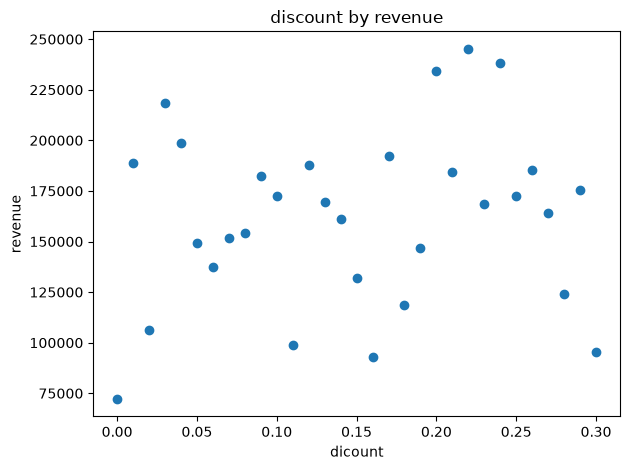

In [139]:
discount=df.groupby("Discount").agg(
    nb=("Discount","count"),
    revenue=("Sales_Amount","sum"),
    quantity=("Quantity_Sold","sum")
).sort_values("revenue",ascending=False)
print(discount.head())

plt.scatter(discount.index, discount["revenue"])
plt.title("discount by revenue")
plt.xlabel("dicount")
plt.ylabel("revenue")
plt.tight_layout()
plt.savefig("../graphes/graphe5")
plt.show()

the best frame of discount the revenue is between the(0.2-0.25);and the 0.22 is the most genret revenue 
0.24 os best for the quantity of sales

                nb_pay     revenue
Payment_Method                    
Bank Transfer      342  1717363.17
Cash               313  1544338.54
Credit Card        345  1757563.52


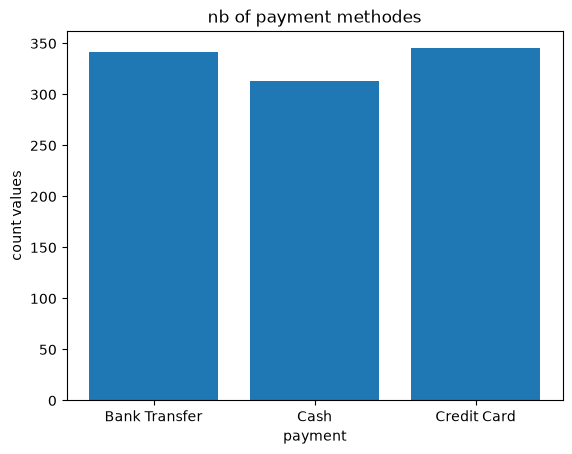

In [140]:
pay=df.groupby("Payment_Method").agg(
    nb_pay=("Payment_Method","count"),
    revenue=("Sales_Amount","sum")
)
print(pay)
plt.bar(pay.index,pay["nb_pay"])
plt.title("nb of payment methodes")
plt.xlabel("payment")
plt.ylabel("count values")
plt.savefig("../graphes/graphe6")
plt.show()


as we see the cash is the last payment method by 313 also in the revenue and the spread btewen them is not to much like 30

In [141]:
sale_cha=df.groupby("Sales_Channel").agg(
    revenue=("Sales_Amount","sum"),
    nb_cha=("Sales_Channel","count")
)
print(sale_cha)


                  revenue  nb_cha
Sales_Channel                    
Online         2458833.93     488
Retail         2560431.30     512


there no big diffrence that influance, the spread is 20 like in the number and 100k in the revenue

In [142]:
region_per=df.pivot_table(
    index="Product_Category",
    columns="Region",
    values="Sales_Amount",
    aggfunc=sum,
)
print(region_per)

Region                 East      North      South       West
Product_Category                                            
Clothing          356670.40  372977.22  269517.74  314309.00
Electronics       303101.42  342666.29  293663.96  304067.97
Food              325864.87  258985.65  301187.51  315735.51
Furniture         274156.24  394983.35  289881.65  301496.45


the North region is number one in the (Clothing,Electronics,Furniture ), but the top one in the food is the East